<center>
    <img src="https://github.com/ajayvasudevancbe-Datascience/Smart-Manufacturing-AI/blob/main/Smart%20Manufacturing%20Workflow.png?raw=true"
         alt="Agricultural Green Crop Field"
         width="700">
</center>

<center>
    <font size="6"><b>Smart Manufacturing AI</b></font>
</center>




# **Problem Statement**

##**Business Context**


## **Objective**

The main objective of Smart Manufacturing AI is to develop an intelligent machine monitoring and failure prediction system using industrial machine sensor data.

This project analyzes machine temperature, rotational speed, torque, tool wear, and operating conditions to understand machine performance and identify potential failures.

Machine Learning and Deep Learning techniques are used to predict machine failures, identify unusual operating behaviour, and support predictive maintenance decisions.


## **Dataset** **Description**

The Smart Manufacturing AI project uses the AI4I 2020 Predictive Maintenance Dataset obtained from the UCI Machine Learning Repository.

This dataset contains industrial machine operating measurements and failure information. It helps analyze machine performance, operating conditions, equipment wear, and maintenance requirements.

The dataset includes important features such as:

- UDI: Unique identifier for each data record.
- Product ID: Unique identification number of the machine product.
- Type: Product quality type (L, M, or H).
- Air Temperature: Temperature of the surrounding environment.
- Process Temperature: Operating temperature during the manufacturing process.
- Rotational Speed: Speed of the machine in revolutions per minute (RPM).
- Torque: Rotational force generated by the machine.
- Tool Wear: Amount of tool usage measured in minutes.
- Machine Failure: Indicates whether the machine has experienced a failure.
- Tool Wear Failure (TWF): Indicates failure caused by tool wear.
- Heat Dissipation Failure (HDF): Indicates failure caused by insufficient heat dissipation.
- Power Failure (PWF): Indicates failure related to power conditions.
- Overstrain Failure (OSF): Indicates failure caused by excessive mechanical stress.
- Random Failure (RNF): Indicates randomly occurring machine failure.



In [1]:
# uncomment and run the following line if using Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Installing and Importing Necessary Libraries**



In this step, we install and import the required Python libraries for data analysis, data visualization, and Machine Learning.

- Pandas: Used for loading and analyzing datasets.
- NumPy: Used for numerical calculations.
- Matplotlib: Used for creating graphs and charts.
- Seaborn: Used for data visualization and statistical graphs.
- Scikit-learn: Used for data preprocessing, model training, and evaluation.



In [140]:
# Import necessary libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


## **Loaded** **Dataset**

1. Original Dataset: AI4I 2020 Predictive Maintenance Dataset.
2. Data Source: UCI Machine Learning Repository.
3. Dataset Name: AI4I 2020 Predictive Maintenance Dataset.
4. Data Period: Synthetic industrial machine operating data; it does not represent a real-world historical monitoring period.
5. File Format: CSV.
6. Original Dataset Size: 10,000 records × 14 columns.
7. Filtered Dataset Size: To be determined after data cleaning and filtering.
8. Selected Parameters: UDI, Product ID, Type, Air Temperature, Process Temperature, Rotational Speed, Torque, Tool Wear, and machine failure indicators.
9. Important Parameters: Air temperature, process temperature, rotational speed, torque, tool wear, and machine failure status.

10\. Target Variable: Machine Failure (`Machine failure`).



In [85]:

df= pd.read_csv(
    '/content/drive/MyDrive/GEN AI DATASET/ai4i2020.csv'
)
print("datasets loaded successfully!")

datasets loaded successfully!


## **Data Overview**

The data overview step helps us understand the structure, size, features, and statistical characteristics of the BatteryMind dataset.

We examine the dataset records, column names, data types, numerical distributions, and missing values.

This analysis provides an initial understanding of the EV battery data before performing data cleaning, preprocessing, and exploratory data analysis.

**1.Display First Five Records: Shows the first five rows of the dataset.**

In [86]:
df.head(6)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0


**2.Display Last Five Records: Shows the last five rows of the dataset.**

In [87]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


**Dataset Dimensions: Displays the total number of rows and columns.**





In [88]:
print("Dataset Shape:", df.shape)

Dataset Shape: (10000, 14)


**Column Names: Lists all the available dataset features.**

In [89]:
print("\nDataset Columns:")
print(df.columns.tolist())


Dataset Columns:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


**Dataset Information: Displays column names, data types, and non-null values.**

In [90]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes

**Statistical Summary: Provides statistical details such as count, mean, standard deviation, minimum, and maximum values.**





In [91]:
print("\nStatistical Summary:")
display(df.describe())



Statistical Summary:


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


**Missing Value Count: Identifies the number of missing values in each column.**

In [92]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


**Duplicate Records: Counts duplicate rows in the dataset.**

In [93]:
print("\nDuplicate Records:", df.duplicated().sum())



Duplicate Records: 0


# **Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) is the process of analyzing and visualizing a dataset to understand its patterns, trends, distributions, and relationships between variables.

EDA helps identify missing values, outliers, unusual patterns, and important features before building Machine Learning models.

**Types of EDA**
1. **Univariate Analysis:** Analyzes one variable at a time to understand its distribution.
2. **Bivariate Analysis:** Analyzes two variables to identify relationships between them.


## **Univariate Analysis**

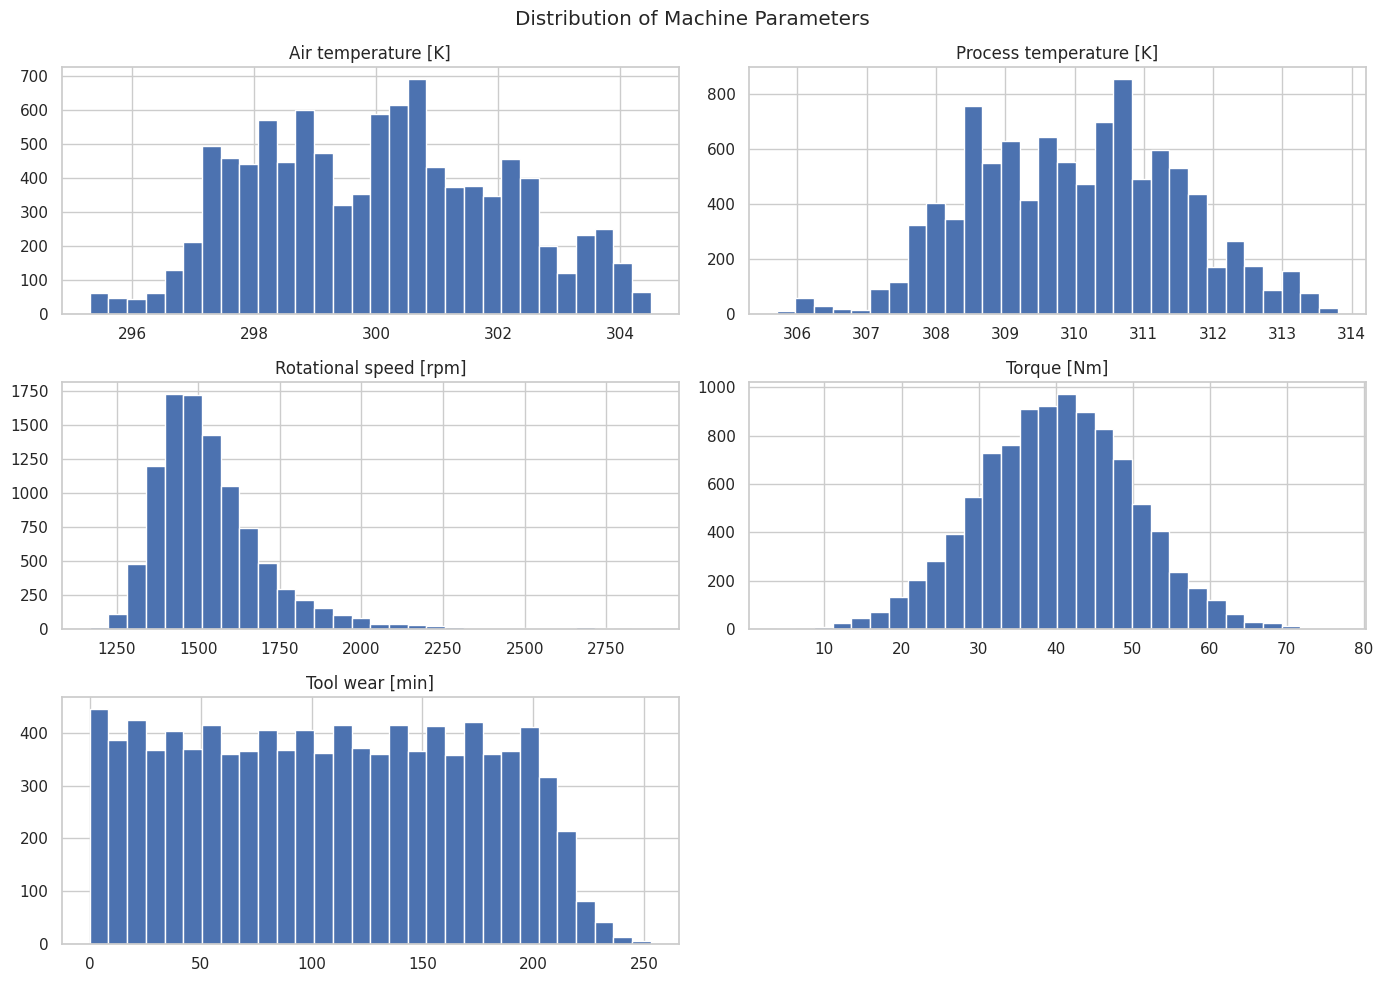

In [103]:
import matplotlib.pyplot as plt

numerical_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

df[numerical_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Distribution of Machine Parameters")
plt.tight_layout()
plt.show()

**Observation**

1. Air temperature and process temperature show relatively consistent distributions with small variations in operating conditions.
2. Rotational speed and torque display variations, indicating differences in machine speed and mechanical load.
3. Tool wear shows different usage levels across machine records, helping identify potential maintenance requirements.

This chart visualizes the distribution of the overall battery State of Health across the dataset.

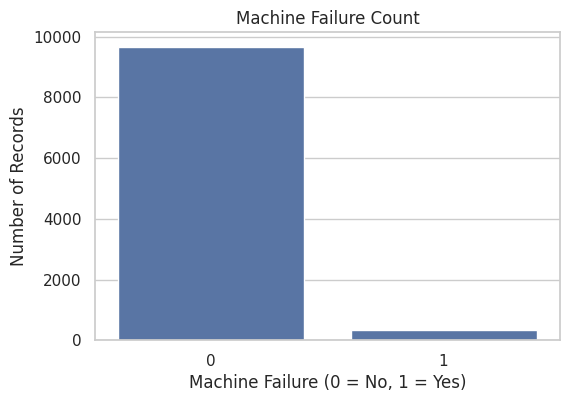

In [108]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='Machine failure'
)

plt.title("Machine Failure Count")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

**Observation**

1. The bar chart shows the number of machines that experienced failure and those that operated without failure.
2. The majority of machine records belong to the non-failure category, while a smaller number indicate machine failures.
3. The chart highlights an imbalance between failure and non-failure records, which is important when developing Machine Learning models.

Analyzing the operating temperatures of the battery pack to understand heat distributions.

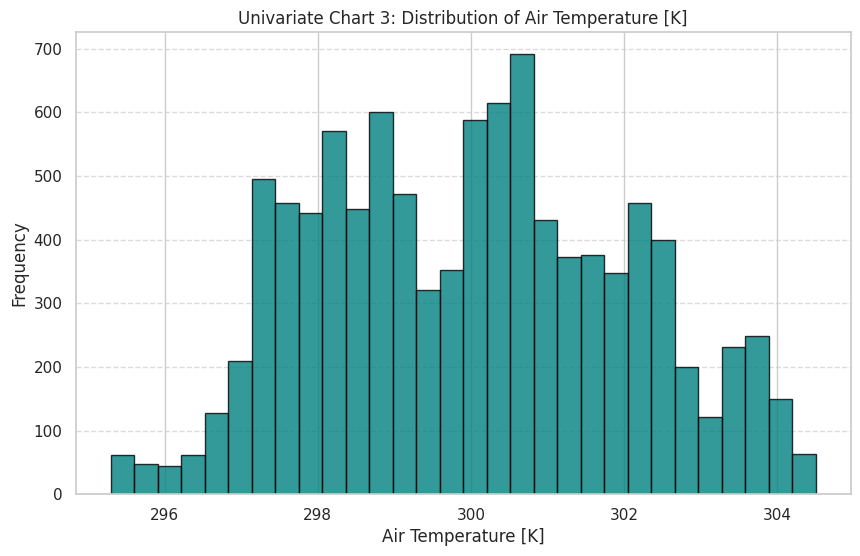

In [98]:
import matplotlib.pyplot as plt

# Univariate Chart 3: Distribution of Air Temperature
plt.figure(figsize=(10, 6))
plt.hist(df['Air temperature [K]'].dropna(), bins=30, color='teal', edgecolor='black', alpha=0.8)
plt.title('Univariate Chart 3: Distribution of Air Temperature [K]')
plt.xlabel('Air Temperature [K]')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Observation**
1. The histogram shows the frequency distribution of air temperature measurements in the dataset.
2. Most air temperature values are concentrated within a relatively narrow range, indicating stable environmental conditions.
3. The chart helps understand temperature variations and identify unusual readings that may affect machine performance.

## **Bivariate** **Analysis**


Next, we explore relationships and trends between pairs of key features.

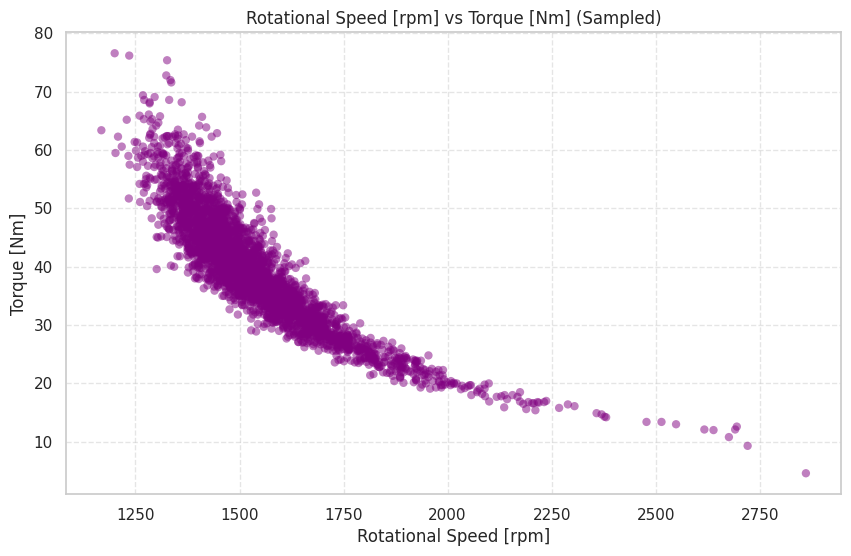

In [104]:
import matplotlib.pyplot as plt

# Bivariate Chart 1: Rotational Speed vs Torque
df_sample = df.sample(min(3000, len(df)), random_state=42)
plt.figure(figsize=(10, 6))
plt.scatter(df_sample['Rotational speed [rpm]'], df_sample['Torque [Nm]'], color='purple', alpha=0.5, edgecolor='none')
plt.title('Rotational Speed [rpm] vs Torque [Nm] (Sampled)')
plt.xlabel('Rotational Speed [rpm]')
plt.ylabel('Torque [Nm]')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Observation**

1. The scatter plot shows the relationship between rotational speed and torque values of industrial machines.
2. The chart indicates that torque generally decreases as rotational speed increases, showing a negative relationship.
3. The visualization helps understand variations in machine operating conditions and mechanical load.

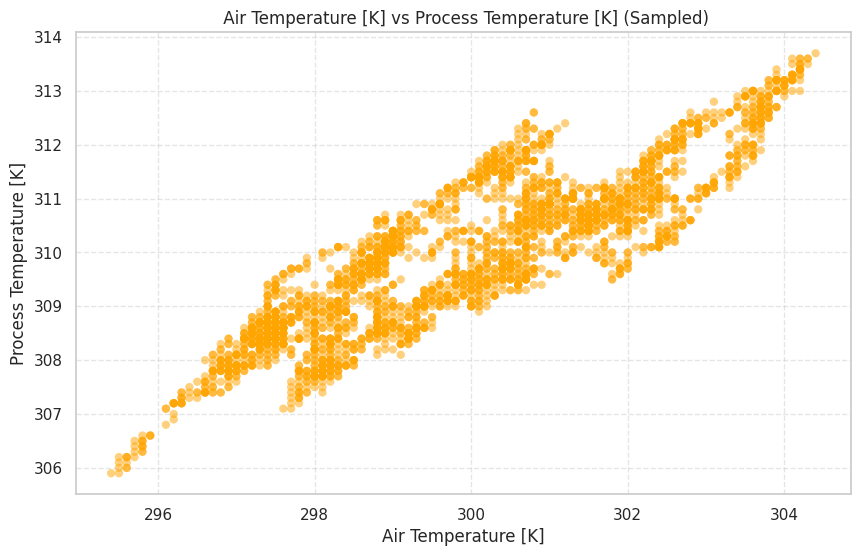

In [105]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df_sample['Air temperature [K]'], df_sample['Process temperature [K]'], color='orange', alpha=0.5, edgecolor='none')
plt.title(' Air Temperature [K] vs Process Temperature [K] (Sampled)')
plt.xlabel('Air Temperature [K]')
plt.ylabel('Process Temperature [K]')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Observation**

1. The scatter plot shows a positive relationship between air temperature and process temperature.
2. Process temperature generally increases as air temperature increases.
3. The chart helps understand the influence of surrounding temperature on machine operating temperature.

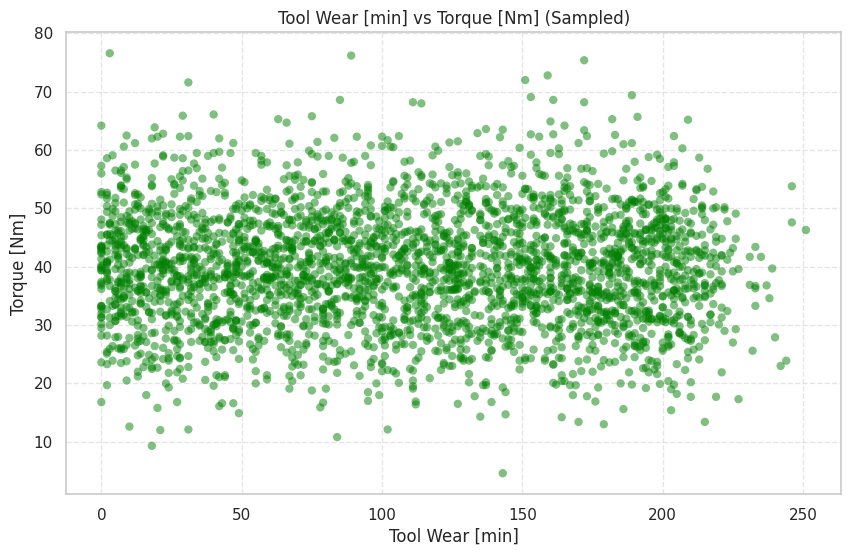

In [106]:
import matplotlib.pyplot as plt

# Bivariate Chart 3: Tool Wear vs Torque
plt.figure(figsize=(10, 6))
plt.scatter(df_sample['Tool wear [min]'], df_sample['Torque [Nm]'], color='green', alpha=0.5, edgecolor='none')
plt.title('Tool Wear [min] vs Torque [Nm] (Sampled)')
plt.xlabel('Tool Wear [min]')
plt.ylabel('Torque [Nm]')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Observation**

1. The scatter plot shows the relationship between tool wear and torque values.
2. Torque values are distributed across different levels of tool wear, indicating variations in mechanical load.
3. The chart helps analyze the relationship between tool usage and machine operating conditions for predictive maintenance.


Represents the proportion of machine failure
and non-failure records in the dataset.

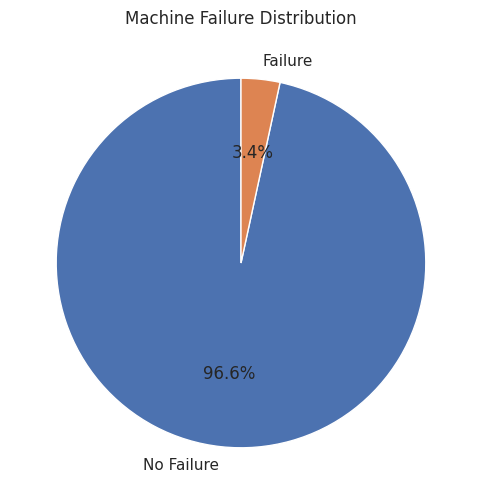

In [109]:
failure_counts = df['Machine failure'].value_counts().sort_index()

plt.figure(figsize=(6, 6))

plt.pie(
    failure_counts,
    labels=['No Failure', 'Failure'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Machine Failure Distribution")
plt.show()

**Observation**
1. The pie chart shows the percentage of machines with and without failures.
2. Most machines operate without failure, while a smaller proportion experience failures.
3. This indicates a class imbalance in the dataset, which should be considered during machine learning model training.

## **Correlation Heatmap**

A correlation heatmap represents the relationships between numerical variables in the dataset. It helps identify positive and negative correlations between machine operating conditions.

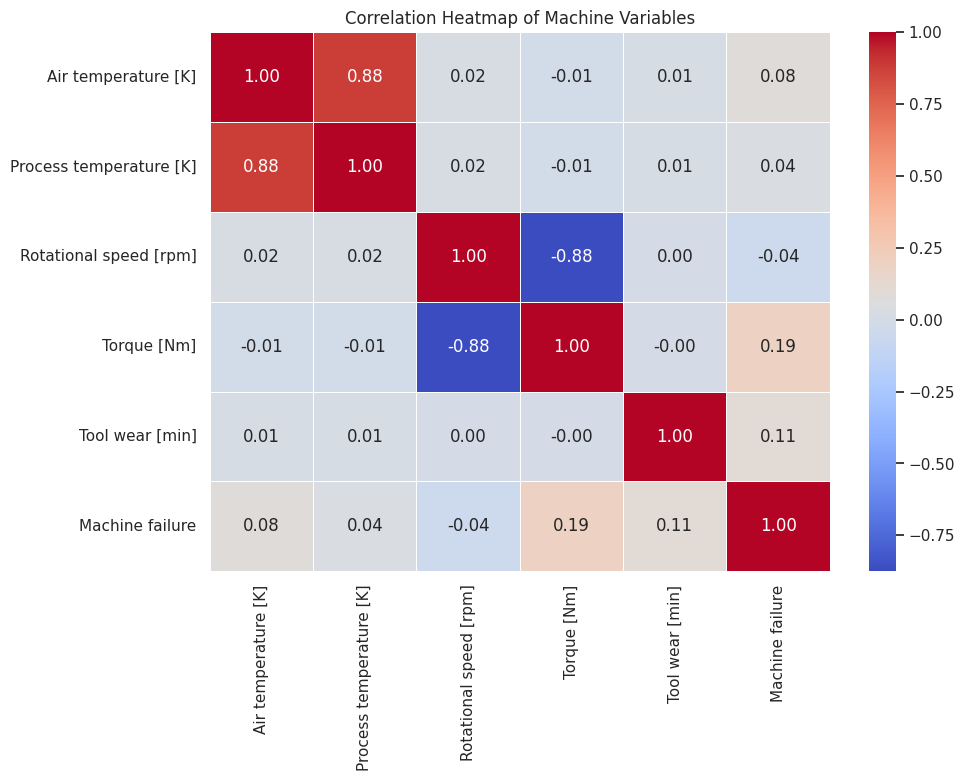

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Machine failure'
]

correlation = df[numerical_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Machine Variables')
plt.show()



**Observation**

1. The heatmap displays the correlation between numerical machine variables.
2. Air temperature and process temperature generally show a positive correlation, while rotational speed and torque show a negative correlation.
3. The correlation values help identify relationships between machine conditions and failure prediction.

# **Feature Engineering**


In this project, new features are created using machine sensor data, such as air temperature, process temperature, rotational speed, torque, and tool wear.

The newly created features include temperature difference, mechanical power, and tool wear categories. These features help analyze machine operating conditions and improve machine failure prediction.

In [112]:


# 1. Temperature Difference
df['Temperature Difference [K]'] = (
    df['Process temperature [K]'] -
    df['Air temperature [K]']
)

# 2. Mechanical Power
df['Power [W]'] = (
    2 * np.pi *
    df['Rotational speed [rpm]'] *
    df['Torque [Nm]'] / 60
)

# 3. Tool Wear Category
df['Tool Wear Category'] = pd.cut(
    df['Tool wear [min]'],
    bins=[-1, 50, 150, 250, float('inf')],
    labels=['Low', 'Medium', 'High', 'Very High']
)

# Display newly created features
df[[
    'Temperature Difference [K]',
    'Power [W]',
    'Tool Wear Category'
]].head()

,Temperature Difference [K],Power [W],Tool Wear Category
0,10.5,6951.590560,Low
1,10.5,6826.722724,Low
2,10.4,7749.387543,Low
3,10.4,5927.504659,Low
4,10.5,5897.816608,Low


**Feature Analysis**

In [113]:
# Display statistical summary of engineered features

df[[
    'Temperature Difference [K]',
    'Power [W]',
    'Tool Wear Category'
]].describe(include='all')

,Temperature Difference [K],Power [W],Tool Wear Category
count,10000.000000,10000.000000,10000
unique,NaN,NaN,4
top,NaN,NaN,Medium
freq,NaN,NaN,4566
mean,10.000630,6279.744953,NaN
std,1.001094,1067.418295,NaN
min,7.600000,1148.440610,NaN
25%,9.300000,5561.184484,NaN
50%,9.800000,6271.027344,NaN
75%,11.000000,7003.002724,NaN


**Visualize Engineered Features**

Feature visualization is used to understand the distribution of newly created features. Histograms help identify common values and variations in temperature difference and mechanical power.

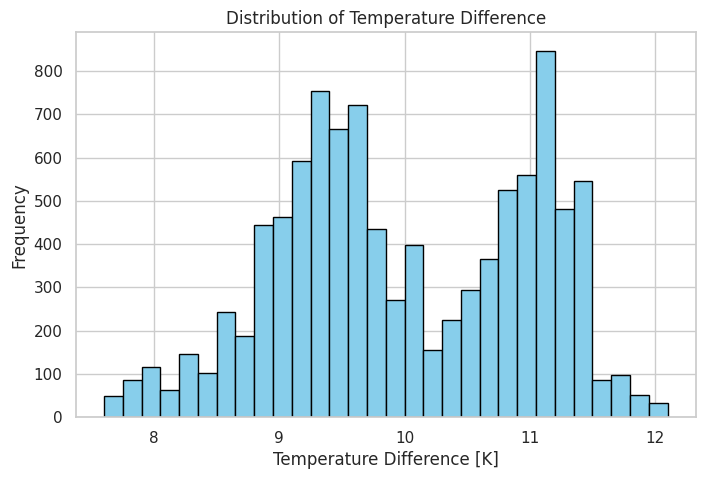

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['Temperature Difference [K]'], bins=30,
         color='skyblue', edgecolor='black')
plt.title('Distribution of Temperature Difference')
plt.xlabel('Temperature Difference [K]')
plt.ylabel('Frequency')
plt.show()

**Feature Relationship with Machine Failure**

This visualization shows the distribution of mechanical power generated by machines. It helps understand variations in machine power under different operating conditions.

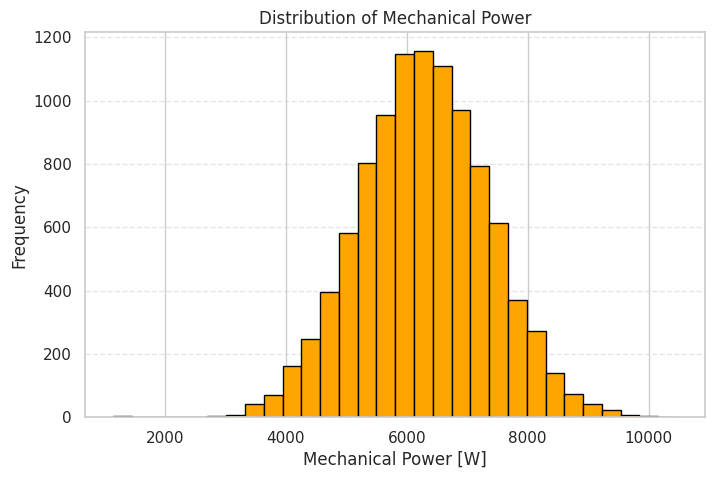

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df['Power [W]'],
    bins=30,
    color='orange',
    edgecolor='black'
)

plt.title('Distribution of Mechanical Power')
plt.xlabel('Mechanical Power [W]')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

**Feature Validation**

In [116]:
# Check missing values in engineered features

engineered_features = [
    'Temperature Difference [K]',
    'Power [W]',
    'Tool Wear Category'
]

print("Missing Values:")
print(df[engineered_features].isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nFeature Data Types:")
print(df[engineered_features].dtypes)

Missing Values:
Temperature Difference [K]    0
Power [W]                     0
Tool Wear Category            0
dtype: int64

Duplicate Records:
0

Feature Data Types:
Temperature Difference [K]     float64
Power [W]                      float64
Tool Wear Category            category
dtype: object


**Final Feature Preparation**

In [117]:
# Define target variable
target = 'Machine failure'

# Remove identifiers and failure-mode columns from input features
drop_columns = [
    'UDI',
    'Product ID',
    'Machine failure',
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF'
]

# Prepare input features and target
X = df.drop(columns=drop_columns)
y = df[target]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Feature Columns:")
print(X.columns.tolist())

Input Features Shape: (10000, 9)
Target Shape: (10000,)

Input Feature Columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature Difference [K]', 'Power [W]', 'Tool Wear Category']


**Observation**

* New features were generated using existing machine sensor measurements.
* Feature analysis and visualization helped understand machine operating conditions.

* The final feature dataset is organized for machine learning model development.





# **Data Preprocessing**

**Encoding Categorical Variables**

- Machine Learning models accept only **numerical data**.
- Convert categorical features into numbers using **One-Hot Encoding** or **Dummy Encoding**.

**Train-Test Split**

- Split the dataset into **Training** and **Testing** data.
- **80%** of the data is used for training.
- **20%** of the data is used for testing.












In [118]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (8000, 9)
Testing Features: (2000, 9)
Training Target: (8000,)
Testing Target: (2000,)


**Categorical Feature Encoding**

Categorical encoding converts text-based categorical features into numerical representations. Machine learning algorithms require numerical input, so categorical variables such as Type and Tool Wear Category must be encoded.

In [119]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=['number']
).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

# Create categorical encoder
encoder = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_cols)
    ],
    remainder='passthrough'
)

# Fit on training data and transform both datasets
X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("\nTraining Data After Encoding:", X_train_encoded.shape)
print("Testing Data After Encoding:", X_test_encoded.shape)

Categorical Columns: ['Type', 'Tool Wear Category']
Numerical Columns: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature Difference [K]', 'Power [W]']

Training Data After Encoding: (8000, 14)
Testing Data After Encoding: (2000, 14)


**Numerical Feature Scaling**

Feature scaling transforms numerical features into a comparable range. It prevents variables with large numerical values from dominating algorithms that are sensitive to feature magnitude.

In [120]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns in the original training data
numerical_cols = X_train.select_dtypes(
    include=['number']
).columns.tolist()

# Fit scaler on training data
scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Scale numerical columns after the encoded categorical columns
number_of_categorical_features = (
    X_train_encoded.shape[1] - len(numerical_cols)
)

X_train_scaled[:, number_of_categorical_features:] = (
    scaler.fit_transform(
        X_train_encoded[:, number_of_categorical_features:]
    )
)

X_test_scaled[:, number_of_categorical_features:] = (
    scaler.transform(
        X_test_encoded[:, number_of_categorical_features:]
    )
)

print("Training Data After Scaling:", X_train_scaled.shape)
print("Testing Data After Scaling:", X_test_scaled.shape)

Training Data After Scaling: (8000, 14)
Testing Data After Scaling: (2000, 14)


**Class Imbalance Analysis**

* Class imbalance occurs when one target class
contains significantly more records than another. In this project, non-failure records are more common than failure records.

* Class distribution is examined to understand the imbalance before applying a suitable balancing technique.

Training Class Distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64


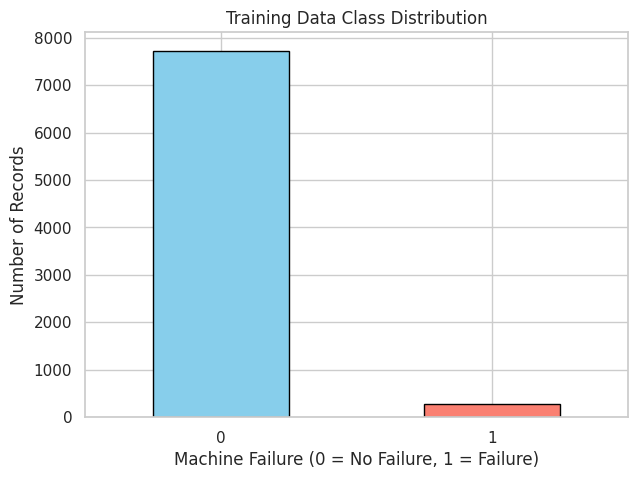

In [121]:
import matplotlib.pyplot as plt

print("Training Class Distribution:")
print(y_train.value_counts())

plt.figure(figsize=(7, 5))

y_train.value_counts().sort_index().plot(
    kind='bar',
    color=['skyblue', 'salmon'],
    edgecolor='black'
)

plt.title('Training Data Class Distribution')
plt.xlabel('Machine Failure (0 = No Failure, 1 = Failure)')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.show()

**Class Balancing Using Random Oversampling**

Random oversampling is a class balancing technique that increases the number of minority-class records by randomly duplicating existing minority-class samples. It is applied only to training data to avoid data leakage.

In [122]:
# Install imbalanced-learn if required
# !pip install imbalanced-learn

from imblearn.over_sampling import RandomOverSampler

# Apply balancing only to training data
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_scaled,
    y_train
)

print("Class Distribution Before Balancing:")
print(y_train.value_counts())

print("\nClass Distribution After Balancing:")
print(y_train_balanced.value_counts())

print("\nBalanced Training Shape:", X_train_balanced.shape)

Class Distribution Before Balancing:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Class Distribution After Balancing:
Machine failure
0    7729
1    7729
Name: count, dtype: int64

Balanced Training Shape: (15458, 14)


**Final Preprocessed Dataset Preparation**

In [123]:
# Display final dataset dimensions

print("Final Preprocessed Dataset")
print("--------------------------------")

print("Balanced Training Features:", X_train_balanced.shape)
print("Balanced Training Target:", y_train_balanced.shape)

print("Testing Features:", X_test_scaled.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train_balanced.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Final Preprocessed Dataset
--------------------------------
Balanced Training Features: (15458, 14)
Balanced Training Target: (15458,)
Testing Features: (2000, 14)
Testing Target: (2000,)

Training Class Distribution:
Machine failure
0    7729
1    7729
Name: count, dtype: int64

Testing Class Distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


**Observation**
1. Training data is cleaned, encoded, scaled, and balanced.
2. Testing data is encoded and scaled without class balancing.
3. The final datasets are ready for machine learning model development.

# **Model Building**

## **Model** **Evaluation**

After training the machine failure prediction models, we evaluate their performance using Accuracy, Precision, Recall, and F1-Score.

Possible Errors:

- False Positive (FP) – Model predicts machine failure, but the machine does not actually fail.
- False Negative (FN) – Model predicts no failure, but the machine actually fails.

> Note: False Negative is more risky because the model fails to identify an actual machine failure, which may lead to unexpected machine breakdowns and maintenance costs.

**Evaluation Metrics:**

- Maximize Accuracy → Higher accuracy means more correct predictions overall.
- Maximize Precision → Higher precision means fewer false failure alerts.
- Maximize Recall → Higher recall means the model identifies more actual machine failures.
- Maximize F1-Score → Higher F1-score indicates a better balance between precision and recall.

**Purpose:**

- Check the performance of the machine learning model.
- Identify incorrect failure predictions.
- Reduce the risk of unexpected machine breakdowns.
- Compare models and select the best-performing model.

In [125]:
import pandas as pd

# Create a blank DataFrame to store model evaluation results
model_eval_results = pd.DataFrame(columns=[
    'Model',
    'Train_Accuracy',
    'Test_Accuracy',
    'Precision',
    'Recall',
    'F1_Score'
])

print("Blank Model Evaluation DataFrame Created")
display(model_eval_results)

Blank Model Evaluation DataFrame Created


,Model,Train_Accuracy,Test_Accuracy,Precision,Recall,F1_Score


### **Logistic Regression Model**

In [126]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression Model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_balanced, y_train_balanced)

# Training predictions
lr_train_pred = lr_model.predict(X_train_balanced)

# Testing predictions
lr_test_pred = lr_model.predict(X_test_scaled)

print("Logistic Regression Model Training Completed")

Logistic Regression Model Training Completed


In [128]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate Logistic Regression performance
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, lr_test_pred),
    "Precision": precision_score(y_test, lr_test_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_test_pred, zero_division=0),
    "F1-Score": f1_score(y_test, lr_test_pred, zero_division=0)
}

# Create DataFrame
performance_df = pd.DataFrame([lr_results])

# Display DataFrame
performance_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8645,0.187692,0.897059,0.310433


**Observation**

- The Logistic Regression model achieved 86.45% accuracy.
- Precision was 18.77%, indicating that many predicted failures were incorrect.
- Recall was 89.71%, meaning the model identified most actual machine failures.
- The F1-score was 31.04%, showing a weak balance between precision and recall.
- Overall, the model detected most machine failures but produced many false failure predictions.

### **Support Vector Machine (SVM) Model**

Support Vector Machine (SVM) is a supervised machine learning classification algorithm. It identifies an optimal decision boundary to classify machine conditions as failure or non-failure.

In [129]:
from sklearn.svm import SVC

# Initialize SVM model
svm_model = SVC(kernel='rbf')

# Train the model
svm_model.fit(X_train_balanced, y_train_balanced)

# Generate predictions
svm_train_pred = svm_model.predict(X_train_balanced)
svm_test_pred = svm_model.predict(X_test_scaled)

print("SVM Model Training Completed")

SVM Model Training Completed


In [130]:
# Calculate SVM performance
svm_results = {
    "Model": "SVM",
    "Accuracy": accuracy_score(y_test, svm_test_pred),
    "Precision": precision_score(y_test, svm_test_pred, zero_division=0),
    "Recall": recall_score(y_test, svm_test_pred, zero_division=0),
    "F1-Score": f1_score(y_test, svm_test_pred, zero_division=0)
}

# Add SVM results to the existing DataFrame
performance_df = pd.concat(
    [performance_df, pd.DataFrame([svm_results])],
    ignore_index=True
)

# Display performance DataFrame
performance_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8645,0.187692,0.897059,0.310433
1,SVM,0.9230,0.299065,0.941176,0.453901


**Observation**

- The SVM model achieved 92.30% accuracy on the test dataset.
- The model achieved 94.12% recall, indicating that it correctly identifies most actual machine failures.
- The 29.91% precision indicates that some non-failure cases are incorrectly predicted as failures.
- The F1-Score of 45.39% shows that there is room to improve the balance between Precision and Recall.
- Overall, the model identifies most machine failures but produces a relatively high number of false failure predictions.

### **XGBoost**

The XGBoost model is evaluated using Accuracy, Precision, Recall, and F1-Score. Its performance results are added to the existing DataFrame to compare all three machine learning models.

In [132]:
from xgboost import XGBClassifier

# Initialize XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    eval_metric='logloss',
    random_state=42
)

# Train the model
xgb_model.fit(X_train_balanced, y_train_balanced)

# Generate predictions
xgb_train_pred = xgb_model.predict(X_train_balanced)
xgb_test_pred = xgb_model.predict(X_test_scaled)

print("XGBoost Model Training Completed")

XGBoost Model Training Completed


In [133]:
# Calculate XGBoost performance
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, xgb_test_pred),
    "Precision": precision_score(y_test, xgb_test_pred, zero_division=0),
    "Recall": recall_score(y_test, xgb_test_pred, zero_division=0),
    "F1-Score": f1_score(y_test, xgb_test_pred, zero_division=0)
}

# Add XGBoost results to the existing DataFrame
performance_df = pd.concat(
    [performance_df, pd.DataFrame([xgb_results])],
    ignore_index=True
)

# Display all model performance results
performance_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8645,0.187692,0.897059,0.310433
1,SVM,0.9230,0.299065,0.941176,0.453901
2,XGBoost,0.9750,0.595745,0.823529,0.691358


**Observation**

- The XGBoost model achieved 97.50% accuracy on the test dataset.
- The model achieved 59.57% precision, indicating that some predicted machine failures are incorrect.
- The 82.35% recall shows that the model identifies most actual machine failures.
- The F1-Score of 69.14% indicates a good balance between Precision and Recall.


### **Model** **Comparison**

Compare all three models and identify the best based on the available results.

<div class="comparison-image">
    <img src="https://github.com/ajayvasudevancbe-Datascience/Smart-Manufacturing-AI/blob/main/Machine%20Failure%20Prediction%20Model%20Comparison.png?raw=true"
         alt="Machine Failure Prediction Model Comparison"
         width="80%">
</div>

# **Deep Learning Model Development (ANN)**

Artificial Neural Network (ANN) is a Deep Learning algorithm inspired by the human brain. It consists of interconnected layers that learn complex patterns from machine sensor data to predict whether a machine will fail or not.

In [135]:
# Initialize ANN model
dl_model = Sequential()

# Input layer and first hidden layer
dl_model.add(Dense(
    64,
    activation='relu',
    input_shape=(X_train_balanced.shape[1],)
))

# Second hidden layer
dl_model.add(Dense(32, activation='relu'))

# Dropout layer
dl_model.add(Dropout(0.2))

# Output layer
dl_model.add(Dense(1, activation='sigmoid'))

# Compile the model
dl_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = dl_model.fit(
    X_train_balanced,
    y_train_balanced,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("ANN Model Training Completed")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Epoch 1/20
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8405 - loss: 0.3649 - val_accuracy: 0.8503 - val_loss: 0.3708
Epoch 2/20
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8997 - loss: 0.2442 - val_accuracy: 0.8955 - val_loss: 0.2743
Epoch 3/20
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9218 - loss: 0.2051 - val_accuracy: 0.8959 - val_loss: 0.2930
Epoch 4/20
387/387 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9294 - loss: 0.1847 - val_accuracy: 0.9428 - val_loss: 0.2101
Epoch 5/20
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9365 - loss: 0.1694 - val_accuracy: 0.9169 - val_loss: 0.2348
Epoch 6/20
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9398 - loss: 0.1583 - val_accuracy: 0.9221 - val_loss: 0.2159
Epoch 7/20
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9455 - loss: 0.1487 - val_accuracy: 0.9324 - val_loss: 0.1858
Epoch 8/20
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9465 - loss: 0.1435 - val_accuracy: 0.

**Observation**
* An Artificial Neural Network is developed using interconnected layers.



* The model learns complex patterns from machine sensor measurements.

* The ANN model is trained to predict machine failure and non-failure cases.

The Artificial Neural Network (ANN) model is evaluated using the test dataset. Accuracy, Precision, Recall, and F1-Score are used to measure its machine failure prediction performance.

In [136]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Generate ANN predictions
dl_test_prob = dl_model.predict(X_test_scaled)

# Convert probabilities into binary predictions
dl_test_pred = (dl_test_prob >= 0.5).astype(int).ravel()

# Calculate ANN performance
dl_results = {
    "Model": "ANN",
    "Accuracy": accuracy_score(y_test, dl_test_pred),
    "Precision": precision_score(y_test, dl_test_pred, zero_division=0),
    "Recall": recall_score(y_test, dl_test_pred, zero_division=0),
    "F1-Score": f1_score(y_test, dl_test_pred, zero_division=0)
}

# Create ANN performance DataFrame
dl_performance_df = pd.DataFrame([dl_results])

# Display results
dl_performance_df

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


,Model,Accuracy,Precision,Recall,F1-Score
0,ANN,0.954,0.417808,0.897059,0.570093


**Observation**

- The ANN model achieved 95.40% accuracy on the test dataset.
- The model achieved 41.78% precision, indicating some predicted machine failures are incorrect.
- The 89.71% recall shows that the model identifies most actual machine failures.
- The F1-Score of 57.01% indicates a moderate balance between Precision and Recall.
- Overall, ANN identifies most machine failures but produces some false failure predictions.

# **Machine Learning and Deep Learning Model Comparison**

The performance of Logistic Regression, SVM, XGBoost, and ANN models is compared using Accuracy, Precision, Recall, and F1-Score. This comparison helps identify the best-performing model for machine failure prediction.

In [137]:
# Combine ML and DL performance results
final_performance_df = pd.concat(
    [performance_df, dl_performance_df],
    ignore_index=True
)

# Sort models by F1-Score
final_performance_df = final_performance_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

# Display final comparison
final_performance_df

,Model,Accuracy,Precision,Recall,F1-Score
0,XGBoost,0.9750,0.595745,0.823529,0.691358
1,ANN,0.9540,0.417808,0.897059,0.570093
2,SVM,0.9230,0.299065,0.941176,0.453901
3,Logistic Regression,0.8645,0.187692,0.897059,0.310433


<div class="comparison-image">
    <img src="https://github.com/ajayvasudevancbe-Datascience/Smart-Manufacturing-AI/blob/main/Machine%20Failure%20Prediction%20Model%20Comparison%20(1).png?raw=true"
         alt="Machine Failure Prediction Model Comparison"
         width="80%">
</div>

## **Prediction** **and** **Analysis**

In [138]:
# Predict machine failures using XGBoost

final_predictions = xgb_model.predict(X_test_scaled)

# Compare actual and predicted values
prediction_results = pd.DataFrame({
    'Actual Machine Failure': y_test.values,
    'Predicted Machine Failure': final_predictions
})

prediction_results.head(10)

,Actual Machine Failure,Predicted Machine Failure
0,0,0
1,0,0
2,0,1
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


In [139]:
# Count correct and incorrect predictions

correct_predictions = (
    prediction_results['Actual Machine Failure'] ==
    prediction_results['Predicted Machine Failure']
).sum()

incorrect_predictions = len(prediction_results) - correct_predictions

print("Total Predictions:", len(prediction_results))
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", incorrect_predictions)

Total Predictions: 2000
Correct Predictions: 1950
Incorrect Predictions: 50


**Observation**

* The XGBoost model predicts machine failure using test data.

* Actual and predicted values are compared

* Correct predictions indicate that the model identified the machine condition accurately

* Incorrect predictions indicate cases where the model failed to match the actual condition.

## **Conclusion**

The Smart Manufacturing AI – Machine Monitoring and Failure Prediction project was developed to predict machine failures using Machine Learning and Deep Learning.

In this project, we used the AI4I 2020 Predictive Maintenance Dataset, which contains 10,000 records of machine operating conditions.

### **Work** **Completed**

1. Dataset Collection: Collected the machine maintenance dataset.
2. Data Understanding: Studied the dataset and understood its columns.
3. Data Cleaning: Checked and removed duplicate and missing records.
4. Data Analysis: Analyzed machine temperature, speed, torque, tool wear, and failures.
5. Feature Engineering: Created new features such as temperature difference and power.
6. Data Preprocessing: Prepared the data for model training.
7. Machine Learning: Built three models: Logistic Regression, SVM, and XGBoost.
8. Deep Learning: Built an ANN model using TensorFlow and Keras.
9. Model Evaluation: Compared all four models using accuracy, precision, recall, and F1-score.
10. Best Model Selection: Selected XGBoost as the best overall model.
11. Failure Prediction: Predicted whether a machine could fail.
12. Dashboard: Created interactive charts to display machine performance and failure results.
13. Streamlit Application: Developed a web application where users can enter machine details and get failure predictions.
14. Deployment: Prepared the project for online deployment.

### **Final** **Results**

Our best model, XGBoost, achieved:

- Accuracy: 97.50%
- Precision: 59.57%
- Recall: 82.35%
- F1-Score: 69.14%

### **Final** **Outcome**

This project helps identify machines that may fail based on their operating conditions. It can help industries plan maintenance and reduce unexpected machine breakdowns.

Through this project, we gained practical knowledge of Python, Machine Learning, Deep Learning, data analysis, model evaluation, Plotly, and Streamlit.

### **Future** **Improvements**

- Connect real-time machine sensors.
- Send alerts when a machine may fail.
- Store prediction history in a database.
- Improve model performance using real factory data.
- Deploy the application online.

Overall, this project demonstrates how AI can help industries monitor machines and predict possible failures before breakdowns occur.